# Can Quantum Kernels Improve EEG-Based Mental Workload Classification?

## Introduction

The Simultaneous Task EEG Workload (STEW) dataset contains electroencephalography (EEG) recordings from 48 participants under resting and multitasking conditions. 
The signals were recorded using a 14-channel EEG headset at a 128 Hz sampling rate.
The participants were asked to rate their workload feeling on a scale of 0 to 9, and we will use this ratings as the ground truth.

### Scope

The objective of this project is to compare different supervised machine learning pipelines to classify mental workload into 'low' (4 or below) or 'high' (5 and above). 

In particular, we will use a dimentionality reduction and a feature selection technique, "PCA" and "ANOVA" respectively, combined with diffent classical models (RBF SVM, Random Forest, Logistic Regression) and a quantum one (Quantum Kernel SVM) to identify which combination achieves the best results.

Article presenting the dataset, with the acquisition methods and a data analysis: [Lim et al, 2018](https://pubmed.ncbi.nlm.nih.gov/30281467/)

Original Dataset (in EDF format) from: [STEW: Simultaneous Task EEG Dataset](https://ieee-dataport.org/open-access/stew-simultaneous-task-eeg-workload-dataset)




In [ ]:
# Python version 3.14.8

%pip install huggingface_hub numpy pandas matplotlib scipy scikit-learn seaborn qiskit qiskit_machine_learning

In [24]:
import os

from huggingface_hub import hf_hub_download

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix
)


## Preprocessing 


### Data Loading 

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)

The data has been converted from raw EEG files into an epoched time series.

In [6]:
REPO_ID = "monster-monash/STEW"

def download_file(filename):
    return hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type="dataset")

X_path = download_file("STEW_X.npy")

Y_path = download_file("STEW_y.csv")

SUBJECT_ID_path = download_file("STEW_subject_id.csv")

X = np.load(X_path)
Y = pd.read_csv(Y_path, header= None).squeeze().to_numpy()
SUBJECT_ID = pd.read_csv(SUBJECT_ID_path, header=None).squeeze().to_numpy()

In [7]:
EEG_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

SAMPLING_FREQUENCY = 128

FREQUENCY_BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 12),
    "beta": (12, 30),
    "gamma": (30, 50),
}

In [8]:
# We verify the shapes of the three arrays

assert(X.ndim == 3)
assert(X.shape == (28512,14,256)) # Expected shape from the tabular dataset description
assert(len(X)==len(Y)==len(SUBJECT_ID))

### Data Cleaning

We remove all the data from subjects 5, 24, 42, as the dataset presentation article (Lim et al, 2018) states that ratings were not obtained for this subjects.

In [9]:
SUBJECTS_TO_REMOVE=[5,24,42]

mask=np.logical_not(np.isin(SUBJECT_ID,SUBJECTS_TO_REMOVE))
X=X[mask]
Y=Y[mask]
SUBJECT_ID=SUBJECT_ID[mask]

In [10]:
#We test that the removal was successful
for subject in SUBJECTS_TO_REMOVE:
    assert(X[SUBJECT_ID==subject].size==0)
    assert(Y[SUBJECT_ID==subject].size==0)
    assert(SUBJECT_ID[SUBJECT_ID==subject].size==0)

    assert(X[SUBJECT_ID==(subject-1)].size!=0)
    assert(Y[SUBJECT_ID==(subject-1)].size!=0)
    assert(SUBJECT_ID[SUBJECT_ID==(subject-1)].size!=0)


assert(X.shape == (28512-28512*3/48,14,256)) # Expected new shape, given that we removed 3/48th of the data.
assert(len(X)==len(Y)==len(SUBJECT_ID))

### Data Exploration

In [15]:
def explore_stew(X, y, subject_ids, sampling_rate):
    X = np.asarray(X)
    y = np.asarray(y).ravel()
    subject_ids = np.asarray(subject_ids).ravel()

    n_epochs, n_channels, n_times = X.shape

    # 1. Overall dataset summary
    summary = pd.DataFrame({
        "Metric": [
            "Number of epochs",
            "Number of channels",
            "Time points per epoch",
            "Sampling rate (Hz)",
            "Duration per epoch (s)",
            "Number of subjects",
            "Number of classes",
            "NaN values",
            "Infinite values",
            "Constant epoch-channel signals"
        ],
        "Value": [
            n_epochs,
            n_channels,
            n_times,
            sampling_rate,
            round(n_times / sampling_rate, 3),
            pd.Series(subject_ids).nunique(),
            pd.Series(y).nunique(),
            int(np.isnan(X).sum()),
            int(np.isinf(X).sum()),
            int((np.nanstd(
                np.where(np.isfinite(X), X, np.nan), axis=2
            ) == 0).sum())
        ]
    })

    # 2. Overall class distribution
    class_counts = (
        pd.Series(y, name="Class")
        .value_counts(dropna=False)
        .rename_axis("Class")
        .reset_index(name="Epoch count")
    )
    class_counts["Percentage (%)"] = (
        100 * class_counts["Epoch count"] / n_epochs
    ).round(2)

    # 3. Epoch count per subject
    subject_counts = (
        pd.DataFrame({"Subject": subject_ids})
        .groupby("Subject", dropna=False)
        .size()
        .reset_index(name="Epoch count")
        .sort_values("Subject")
        .reset_index(drop=True)
    )

    # 4. Class distribution per subject
    subject_class_counts = pd.crosstab(
        pd.Series(subject_ids, name="Subject"),
        pd.Series(y, name="Class"),
        dropna=False
    ).reset_index()

    # 5. Basic signal statistics
    finite_X = np.where(np.isfinite(X), X, np.nan)

    signal_summary = pd.DataFrame({
        "Statistic": [
            "Minimum",
            "Maximum",
            "Mean",
            "Standard deviation",
            "Median absolute amplitude"
        ],
        "Value": [
            np.nanmin(finite_X) if np.isfinite(finite_X).any() else np.nan,
            np.nanmax(finite_X) if np.isfinite(finite_X).any() else np.nan,
            np.nanmean(finite_X),
            np.nanstd(finite_X),
            np.nanmedian(np.abs(finite_X))
        ]
    })

    return {
    "dataset_summary": summary,
    "class_counts": class_counts,
    "subject_counts": subject_counts,
    "subject_class_counts": subject_class_counts,
    "signal_summary": signal_summary
    }

In [17]:
reports = explore_stew(X, Y, SUBJECT_ID, SAMPLING_FREQUENCY)

display(reports["dataset_summary"])
display(reports["class_counts"])
display(reports["subject_counts"])
display(reports["subject_class_counts"])
display(reports["signal_summary"])

,Metric,Value
0,Number of epochs,26730.0
1,Number of channels,14.0
2,Time points per epoch,256.0
3,Sampling rate (Hz),128.0
4,Duration per epoch (s),2.0
5,Number of subjects,45.0
6,Number of classes,2.0
7,NaN values,0.0
8,Infinite values,0.0
9,Constant epoch-channel signals,0.0


,Class,Epoch count,Percentage (%)
0,1,13365,50.0
1,0,13365,50.0


,Subject,Epoch count
0,1,594
1,2,594
2,3,594
3,4,594
4,6,594
5,7,594
6,8,594
7,9,594
8,10,594
9,11,594


Class,Subject,0,1
0,1,297,297
1,2,297,297
2,3,297,297
3,4,297,297
4,6,297,297
5,7,297,297
6,8,297,297
7,9,297,297
8,10,297,297
9,11,297,297


,Statistic,Value
0,Minimum,-7131.082031
1,Maximum,7054.263672
2,Mean,0.431821
3,Standard deviation,95.316826
4,Median absolute amplitude,11.135169


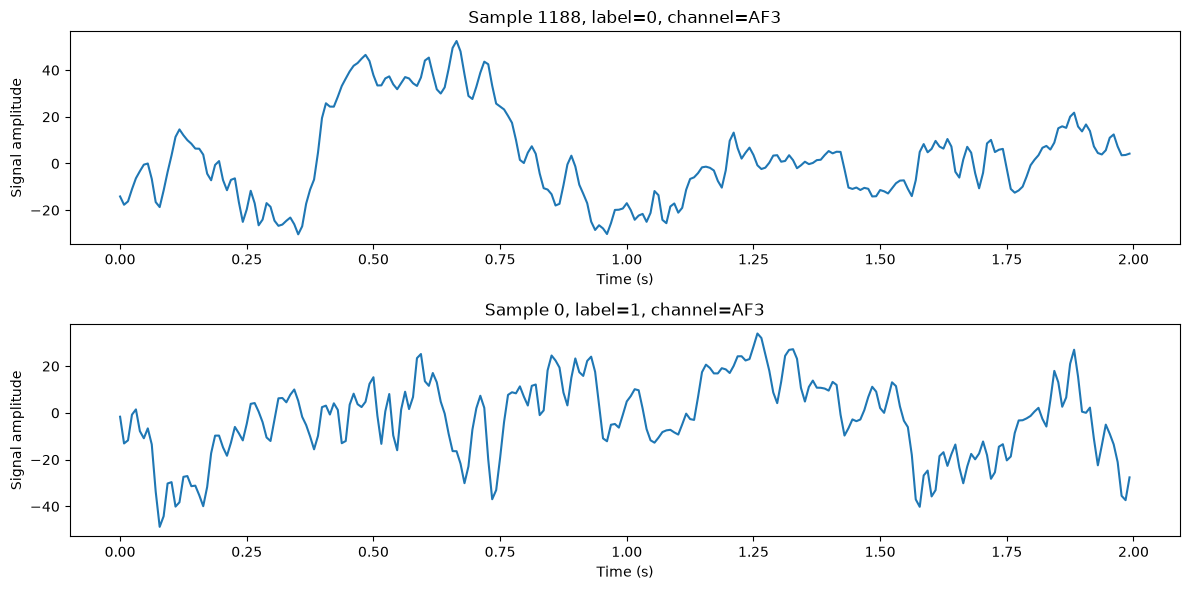

In [30]:
sample_indices = [
    np.flatnonzero(Y == label)[0]
    for label in np.unique(Y)
]

time = np.arange(X.shape[2]) / SAMPLING_FREQUENCY

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

for ax, idx in zip(axes, sample_indices):
    ax.plot(time, X[idx, 0, :])
    ax.set_title(f"Sample {idx}, label={Y[idx]}, channel={EEG_CHANNELS[0]}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Signal amplitude")

plt.tight_layout()
plt.show()

### Feature engineering

We crete a .csv table with the chosen features:

In [12]:
def extract_features(signal):

    # Time-domain features
    new_features = {
        "mean": np.mean(signal),
        "std" : np.std(signal),
        "var" : np.var(signal),
        "rms" : np.sqrt(np.mean(signal**2)),
        "skewness": skew(signal, bias=True),
        "kurtosis": kurtosis(signal, fisher=True, bias=True),
    }
    
    # Frequency-domain features
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=len(signal)
    )

    frequency_resolution = freqs[1] - freqs[0] 

    total_mask = (freqs >= 1) & (freqs < 45)
    total_power = np.sum(psd[total_mask]) * frequency_resolution

    for band, (low, high) in FREQUENCY_BANDS.items():

        mask = (freqs >= low) & (freqs < high)

        power = (
            np.sum(psd[mask]) * frequency_resolution
            if np.any(mask) else 0.0
        )

        new_features[f"{band}_power"] = power

        new_features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 1e-12 else 0.0
        )

    # Spectral entropy over the 1–45 Hz range
    psd_band = psd[total_mask]
    power_sum = psd_band.sum()

    if power_sum > 1e-12:
        probabilities = psd_band / power_sum
        probabilities = probabilities[probabilities > 0]

        new_features["spectral_entropy"] = -np.sum(
            probabilities * np.log2(probabilities)
        )
    else:
        new_features["spectral_entropy"] = 0.0

    return new_features

In [19]:
def create_dataset():
    records = []

    for sample_idx in range(len(X)):

        eeg_sample = X[sample_idx]

        record = {
            "sample_id": sample_idx,
            "subject_id": SUBJECT_ID[sample_idx],
        }

        for channel_idx, channel_name in enumerate(EEG_CHANNELS):

            signal = eeg_sample[channel_idx, :]

            channel_features = extract_features(signal)

            for feature_name, value in channel_features.items():
                column_name = f"{channel_name}_{feature_name}"
                record[column_name] = value

        record["label"] = Y[sample_idx]
        records.append(record)

        if (sample_idx + 1) % 1000 == 0:
            print(f"Processed {sample_idx + 1}/{len(X)} examples")

    print(f"Processed {sample_idx + 1}/{len(X)} examples")
    return records

We create a dataframe with the extracted outputs and write it to a .csv file.

In [20]:
DATASET_PATH = "STEW_features.csv"

if(os.path.isfile(DATASET_PATH)):
    DATASET_EXT=pd.read_csv(DATASET_PATH)
else:
    new_dataset=create_dataset()
    DATASET_EXT = pd.DataFrame(new_dataset)
    
    #Automatically overwrites a file of the same name in this directory.
    DATASET_EXT.to_csv(DATASET_PATH, index=False)
    
print(DATASET_EXT.shape)

(26730, 241)


In [21]:
print(DATASET_EXT.head())
print(DATASET_EXT.shape)

   sample_id  subject_id  AF3_mean    AF3_std    AF3_var    AF3_rms  \
0          0          12 -2.364527  16.718996  279.52484  16.885374   
1          1          12  1.513650  15.534682  241.32635  15.608251   
2          2          12  0.492984  14.909048  222.27971  14.917197   
3          3          12 -2.007783  14.349675  205.91318  14.489458   
4          4          12  1.876135  13.039218  170.02121  13.173500   

   AF3_skewness  AF3_kurtosis  AF3_delta_power  AF3_delta_relative_power  ...  \
0     -0.339354     -0.337851       114.806351                  0.573799  ...   
1     -0.468445     -0.308483       185.131073                  0.716253  ...   
2     -0.283593     -0.254668       141.955475                  0.627093  ...   
3     -0.157667     -0.236524        81.054817                  0.508537  ...   
4     -0.063752     -0.338315        59.304790                  0.397247  ...   

   AF4_theta_power  AF4_theta_relative_power  AF4_alpha_power  \
0       323.099518   

In [22]:
X_ = DATASET_EXT.drop(columns=['sample_id', 'subject_id', 'label'])
y_ = DATASET_EXT['label']
subjects = DATASET_EXT['subject_id']

### Visualisation of the results

c:\Users\vsf24\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
c:\Users\vsf24\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


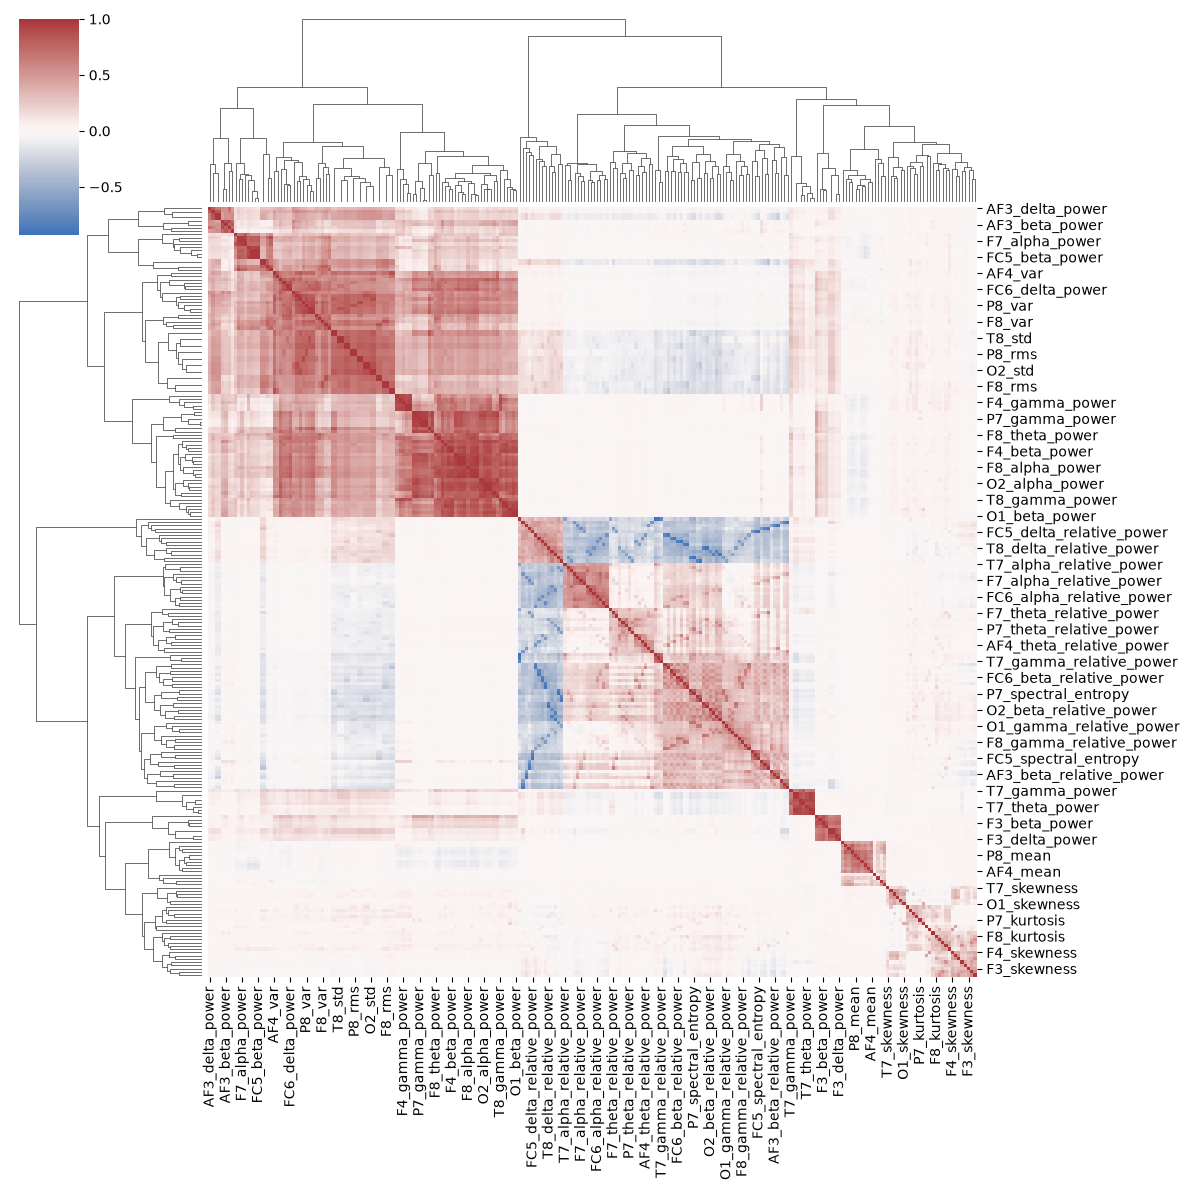

In [25]:
sns.clustermap(
    X_.corr(),
    cmap="vlag",
    center=0,
    figsize=(12, 12)
)
plt.show()

## Model Training

### Pipelines: Features reduction and Model training

We want to analyze the impact of PCA and ANOVA on different SVM models like RBF and Logistic Regression as a guideline.

#### Hyperparameters

In [ ]:
# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [5, 10, 20, 50, 100]

# Main metric used to compare the methods
SCORING = 'f1_weighted'